# Clean SoH model with battery-level split

This notebook trains a battery-health model using a proper battery-level train/test split.
It avoids the leakage issue from using capacity-derived features.

In [6]:
! pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.9 MB/s eta 0:00:27
    --------------------------------------- 1.0/48.9 MB 1.8 MB/s eta 0:00:27
   - -------------------------------------- 1.3/48.9 MB 1.7 MB/s eta 0:00:29
   - -------------------------------------- 1.6/48.9 MB 1.6 MB/s eta 0:00:29
   - -------------------------------------- 1.8/48.9 MB 1.6 MB/s eta 0:00:30
   - -------------------------------------- 2.4/48.9 MB 1.7 MB/s eta 0:00:28
   -- ------------------------------------- 2.6/48.9 MB 1.7 MB/s eta 0:00:27
   -- ------------------------------------- 3.1/48.9 MB 1.7 MB/s eta 0:00:28
   -- ------------------------------------- 3.4/48.9 MB 1.6 MB/s eta 0:00:28
   -- ------------------------------------- 3.4/48.9 MB 1.6 MB/s eta 0:00:28
   -- ------------------------------------- 3.7/48.9 MB 1.6 MB/s eta 0:00:29
   --- ------

Valid batteries: 32
Rows: 2524
Train batteries: ['B0005', 'B0006', 'B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028', 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0039', 'B0041', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0048', 'B0049', 'B0051', 'B0053', 'B0056']
Test batteries : ['B0029', 'B0030', 'B0038', 'B0040', 'B0047', 'B0054', 'B0055']
Train rows: 2078 Test rows: 446
MAE : 0.0072
RMSE: 0.0270
R2  : 0.9494


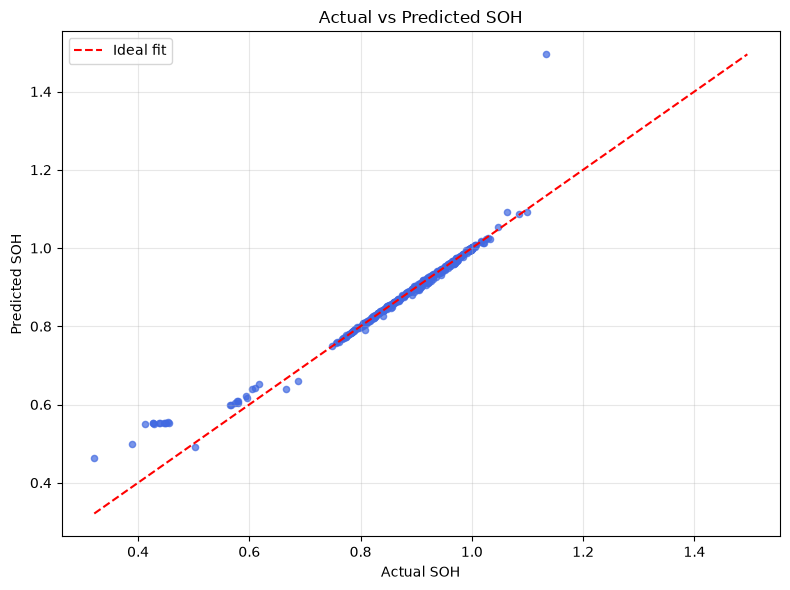

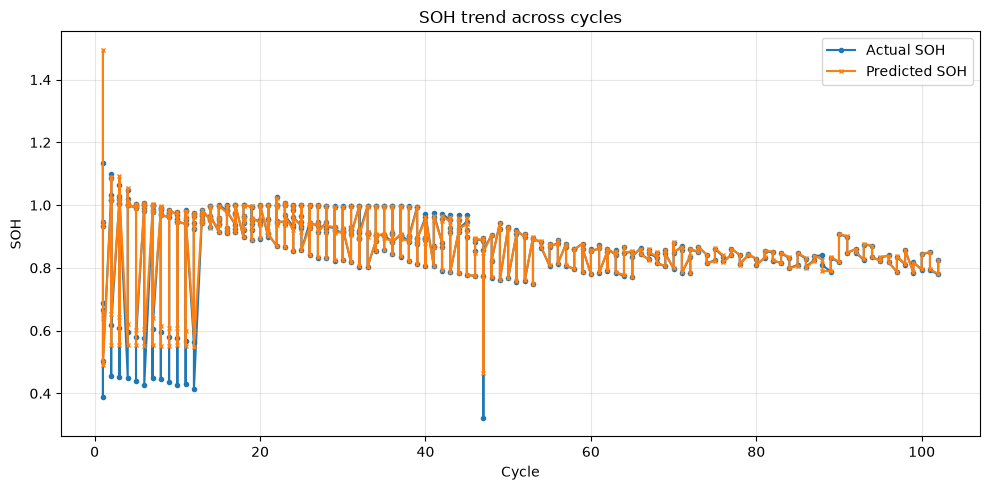

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

np.random.seed(42)

# --------------------------------------------------
# 1) Load data
# --------------------------------------------------
df = pd.read_csv("cycle_summary_soh_rul_FINAL.csv")
df = df.sort_values(["battery_id", "cycle"]).reset_index(drop=True)

# --------------------------------------------------
# 2) Better feature engineering
# Use battery-relative age and degradation features
# --------------------------------------------------
df["cycle_max"] = df.groupby("battery_id")["cycle"].transform("max")
df["cycle_pct"] = df["cycle"] / df["cycle_max"]

df["capacity_ratio"] = df["capacity_Ah"] / df["rated_capacity_Ah"]

feature_cols = [
    "cycle_pct",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    "max_current_A",
    "min_current_A",
    "mean_current_A",
    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",
    "discharge_time_s",
    "rated_capacity_Ah",
    "capacity_ratio"
]

target_col = "soh"

df = df.dropna(subset=feature_cols + [target_col]).copy()

# Keep only batteries with enough data
counts = df["battery_id"].value_counts()
valid_batteries = counts[counts >= 20].index
df = df[df["battery_id"].isin(valid_batteries)].copy()

print("Valid batteries:", len(valid_batteries))
print("Rows:", len(df))

# --------------------------------------------------
# 3) Battery-level split
# --------------------------------------------------
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, df[target_col], groups=df["battery_id"]))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Train batteries:", sorted(train_df["battery_id"].unique()))
print("Test batteries :", sorted(test_df["battery_id"].unique()))
print("Train rows:", len(train_df), "Test rows:", len(test_df))

X_train = train_df[feature_cols].values
y_train = train_df[target_col].values
X_test = test_df[feature_cols].values
y_test = test_df[target_col].values

# --------------------------------------------------
# 4) Model
# XGBoost works better than raw RandomForest for degradation trends
# --------------------------------------------------
model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2  : {r2:.4f}")

# --------------------------------------------------
# 5) Actual vs predicted
# --------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred, s=20, alpha=0.7, color="royalblue")

min_val = min(float(np.min(y_test)), float(np.min(pred)))
max_val = max(float(np.max(y_test)), float(np.max(pred)))

plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal fit")
plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Actual vs Predicted SOH")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Cycle trend plot
test_plot = test_df.sort_values("cycle").copy()
test_plot["predicted_soh"] = model.predict(test_plot[feature_cols].values)

plt.figure(figsize=(10, 5))
plt.plot(test_plot["cycle"], test_plot["soh"], label="Actual SOH", marker="o", markersize=3, linewidth=1.5)
plt.plot(test_plot["cycle"], test_plot["predicted_soh"], label="Predicted SOH", marker="x", markersize=3, linewidth=1.5)
plt.xlabel("Cycle")
plt.ylabel("SOH")
plt.title("SOH trend across cycles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# Load and prepare data
# --------------------------------------------------
df = pd.read_csv("cycle_summary_soh_rul_FINAL.csv")
df = df.sort_values(["battery_id", "cycle"]).reset_index(drop=True)

df["cycle_max"] = df.groupby("battery_id")["cycle"].transform("max")
df["cycle_pct"] = df["cycle"] / df["cycle_max"]
df["capacity_ratio"] = df["capacity_Ah"] / df["rated_capacity_Ah"]

feature_cols = [
    "cycle_pct",
    "max_voltage_V",
    "min_voltage_V",
    "mean_voltage_V",
    "max_current_A",
    "min_current_A",
    "mean_current_A",
    "max_temperature_C",
    "min_temperature_C",
    "mean_temperature_C",
    "discharge_time_s",
    "rated_capacity_Ah",
    "capacity_ratio"
]

target_col = "soh"

df = df.dropna(subset=feature_cols + [target_col]).copy()

counts = df["battery_id"].value_counts()
valid = counts[counts >= 20].index
df = df[df["battery_id"].isin(valid)].copy()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, df[target_col], groups=df["battery_id"]))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

X_train = train_df[feature_cols].values
y_train = train_df[target_col].values
X_test = test_df[feature_cols].values
y_test = test_df[target_col].values

scaler = StandardScaler()
X_train_n = scaler.fit_transform(X_train)
X_test_n = scaler.transform(X_test)

# --------------------------------------------------
# Small DNN
# --------------------------------------------------
model = keras.Sequential([
    keras.layers.Input(shape=(X_train_n.shape[1],)),
    keras.layers.Dense(24, activation="relu"),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(12, activation="relu"),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(1, activation="linear")
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_n,
    y_train,
    validation_split=0.15,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

pred = model.predict(X_test_n, verbose=0).ravel()

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2  : {r2:.4f}")

MAE : 0.0232
RMSE: 0.0427
R2  : 0.8729
